# 현실의 데이터 06: 카드 이상거래 탐지 (보이스피싱 · 자금세탁 등)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/06_card_fraud.ipynb)

**분야**: 금융 · 핀테크 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 이상거래탐지 (FDS) · 보이스피싱 · 송금 사기 · 자금세탁방지 · 설명가능성

> 카드 거래 28만 건 중 사기는 0.17%. 정확도 99.8% 는 좋은 점수일까?

**데이터**: Credit Card Fraud Detection (ULB) (약 150MB). 유럽 카드 소지자의 2013년 9월 이틀치 거래, OpenML 1597 (원본 Kaggle mlg-ulb). 성분은 개인정보 때문에 PCA 로 바꾼 V1~V28. OpenML 판에는 시각 열이 없지만 행이 시간 순서대로 놓여 있다.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 카드 거래 한 건 |
| ② 입력 X | 금액 · V1~V28 |
| ③ 출력 y | 사기인가 (Class 0/1) |
| ④ 평가지표 | 정밀도 · 재현율 (정확도는 함정) |
| ⑤ 기준선 | 전부 '정상' |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Dal Pozzolo et al. (2015) Calibrating Probability with Undersampling for Unbalanced Classification, IEEE SSCI](https://doi.org/10.1109/SSCI.2015.33)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

OpenML 에서 받는다 (약 150MB, 처음엔 1~2분).

In [2]:
from sklearn.datasets import fetch_openml
cc = fetch_openml(data_id=1597, as_frame=True, parser="auto", data_home="data")
df = cc.frame
df["Class"] = df["Class"].astype(int)
print(df.shape)
df.head()

(284807, 30)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 열어 보기

사기 (Class = 1) 는 몇 건일까? 금액은 어떻게 퍼져 있을까? 사기와 정상의 금액이 다를까?

Class
0    284315
1       492
Name: count, dtype: int64
fraud rate: 0.173%
          count   mean    std  min  25%   50%    75%      max
Class                                                        
0      284315.0   88.3  250.1  0.0  5.6  22.0   77.0  25691.2
1         492.0  122.2  256.7  0.0  1.0   9.2  105.9   2125.9


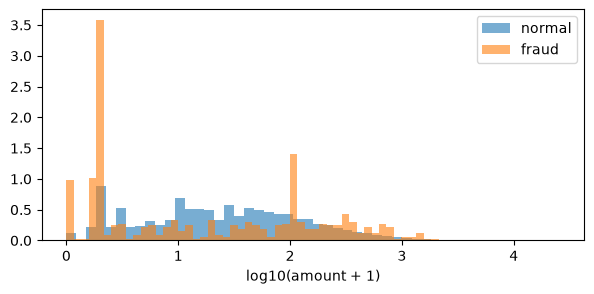

In [3]:
print(df["Class"].value_counts())
print(f"fraud rate: {df['Class'].mean():.3%}")
print(df.groupby("Class")["Amount"].describe().round(1))
plt.figure(figsize=(7, 3))
for c, name in [(0, "normal"), (1, "fraud")]:
    plt.hist(np.log10(df.loc[df["Class"] == c, "Amount"] + 1), bins=50, density=True, alpha=0.6, label=name)
plt.xlabel("log10(amount + 1)"); plt.legend(); plt.show()

## 문제 하나 골라 보기: 거래 하나 → 사기인가

**시간 순서대로** 나눈다: 앞 70% 행으로 학습, 뒤 30% 로 시험 (행이 시간 순서대로 놓여 있다. 미래의 사기를 잡는 게 목적이니까). 기준선 = 전부 '정상'.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

cut = int(len(df) * 0.7)
train, test = df.iloc[:cut], df.iloc[cut:]
X_cols = [c for c in df.columns if c != "Class"]
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(train[X_cols], train["Class"])

y = test["Class"].values
for name, pred in [("always normal", np.zeros(len(y), dtype=int)), ("logistic regression", model.predict(test[X_cols]))]:
    p, r = precision_recall(y, pred)
    print(f"{name:20s} accuracy {np.mean(pred == y):.3%}  precision {p:.0%}  recall {r:.0%}")

always normal        accuracy 99.874%  precision 0%  recall 0%
logistic regression  accuracy 99.917%  precision 77%  recall 49%


**관찰**: 전부 '정상' 도 정확도가 99.8% 를 넘는다. 사기를 하나도 못 잡는데도. 그래서 이 문제는 정밀도 · 재현율로 채점한다.

## 다른 문제로 바꿔 보기

- **보이스피싱**: 피해자가 직접 송금하는 사기라 카드 도용과 모양이 다르다. 한 행 = 송금 한 건, 입력에 '처음 보내는 계좌인가 · 평소보다 큰 금액인가 · 이체 직후 현금 인출이 있었나' 같은 **맥락** 이 필요하다. 이 데이터에는 그런 열이 없다 (송금 사기를 시뮬레이션한 PaySim 데이터가 있다, Kaggle).
- **자금세탁방지**: 한 행이 '거래' 가 아니라 '계좌' 라면? 이 가게의 '자금세탁 거래 탐지' (IBM AML) 노트북에서 해 볼 수 있다.
- **설명가능성**: V1~V28 은 개인정보 때문에 원래 뜻을 지운 숫자다. 이 모델이 '왜' 사기라고 했는지 고객에게 설명할 수 있을까? (7주차 SHAP)
- **컴플라이언스**: 놓친 사기 한 건과, 정상 고객의 카드를 잘못 막은 한 건. 어느 손해가 더 큰가에 따라 지표가 달라진다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |